# INF201 – Deliverable 1: Weather data from Ås

**Authors:** *Mathias Gundersen, Jakub Mermer*  
**GitHub repository:** *https://github.com/saltonese/Del_1-G6_5.git*

Denne notebooken bruker målinger/data fra Meterologisk Institutt (MET) via
[Frost API](https://frost.met.no) for å finne tempreatur, nedbør og hetebølger 
ved værstasjonen i Ås (`SN17850`)

**Client ID** Frost client IDen er personlig og må derfor ikke havne i GitHub repo-en.
Koden nedenfor leser den fra en fil `Frost_ID` lokalt.

In [1]:

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yaml

STATION = "SN17850"          # Ås
YEAR = 2025
TEMP_MEAN = "mean(air_temperature P1D)"
TEMP_MAX = "max(air_temperature P1D)"
PRECIP = "sum(precipitation_amount P1D)"

OBS_URL = "https://frost.met.no/observations/v0.jsonld"
SOURCES_URL = "https://frost.met.no/sources/v0.jsonld"


def load_client_id():
    """Read the Frost client ID from a local file."""

    path = Path.cwd().parent / "Frost_ID.txt"  #filen ligger i parent mappen til notebooken
    if path.is_file():
        return path.read_text(encoding="utf-8").strip()

    raise FileNotFoundError( 
        f"Could not find Frost_ID.txt in the notebook's working directory: {Path.cwd()}"
    )


CLIENT_ID = load_client_id()

## Hjelpe funksjoner: laste inn data fra Frost

Brukte eksempelkoden fra MET ([frost.met.no/python_example.html](https://frost.met.no/python_example.html))
som utgangspunkt. Måtte endre 2 ting:

* `DataFrame.append` finnes ikke i nåværende versjoner av pandas. tabellen ble laget fra en liste med rows istdet
* Frost kan returnere **felere parallele tids-serier for samme dag** (forkjellig `timeOffset`,
  f.eks. `PT0H` og `PT6H`, som betyr at 24-timers perioden starter på forksjellige tidspunkter). Dersom vi ikke endrer på dette ville hver dag komme opp 2 ganger.
  Funksjonen beholder tidsperioden med flest oberservasjoner og forteller oss når den må velge. 

In [2]:
def frost_get(url, params):
    """GET from Frost and return the JSON, raising a readable error if it fails."""
    r = requests.get(url, params=params, auth=(CLIENT_ID, ""), timeout=60)
    payload = r.json()
    if r.status_code != 200:
        err = payload.get("error", {})
        raise RuntimeError(
            f"Frost returned {r.status_code}: {err.get('message')} ({err.get('reason')})"
        )
    return payload


def get_daily(station, element, year):
    """Return a pandas Series (index = date) with one daily value per day of `year`."""
    params = {
        "sources": station,
        "elements": element,
        # Går fra 01-01 til 01-01 neste år for å få med alle dagene.
        "referencetime": f"{year}-01-01/{year + 1}-01-01",
    }
    payload = frost_get(OBS_URL, params)

    rows = [
        {"date": item["referenceTime"], "value": obs["value"], "timeOffset": obs.get("timeOffset")}
        for item in payload["data"]
        for obs in item["observations"]
    ]
    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None).dt.normalize()

    # Several parallel series per day? Keep the one with most observations.
    if df["timeOffset"].nunique() > 1:
        counts = df["timeOffset"].value_counts()
        chosen = counts.idxmax()
        print(f"Note ({element}, {year}): several time offsets {counts.to_dict()}, using {chosen}")
        df = df[df["timeOffset"] == chosen]
    if df["date"].duplicated().any():
        print(f"Warning ({element}, {year}): duplicate dates remain, keeping the first")
        df = df.drop_duplicates("date")

    df = df[df["date"].dt.year == year]
    return df.set_index("date")["value"].sort_index().rename(element)


def resolve_station(station):
    """Accept either a station id ('SN17850') or a station name ('Ås') and return the id."""
    if station.upper().startswith("SN") and station[2:].isdigit():
        return station.upper()
    payload = frost_get(SOURCES_URL, {"name": station})
    matches = {s["id"]: s["name"] for s in payload["data"]}
    exact = [sid for sid, name in matches.items() if name.lower() == station.lower()]
    if len(exact) == 1:
        return exact[0]
    raise ValueError(f"Could not pick a single station for '{station}'. Candidates: {matches}")


def summary_table(series_by_label, unit="°C"):
    """Mean / median / min / max (plus number of days) for one or more series."""
    stats = {
        label: {
            f"Mean ({unit})": f"{s.mean():.1f}",
            f"Median ({unit})": f"{s.median():.1f}",
            f"Min ({unit})": f"{s.min():.1f}",
            f"Max ({unit})": f"{s.max():.1f}",
            "Days with data": f"{s.count()}",
        }
        for label, s in series_by_label.items()
    }
    return pd.DataFrame(stats)

## Task 1: Temperature

In [3]:
temp = get_daily(STATION, TEMP_MEAN, YEAR)
print(f"Samlet {len(temp)} dager med data")   # Viser hvor mange dager med data
temp.head()

Note (mean(air_temperature P1D), 2025): several time offsets {'PT0H': 365, 'PT6H': 365}, using PT0H
Samlet 365 dager med data


date
2025-01-01    -5.2
2025-01-02   -11.5
2025-01-03    -8.9
2025-01-04   -15.5
2025-01-05   -12.5
Name: mean(air_temperature P1D), dtype: float64

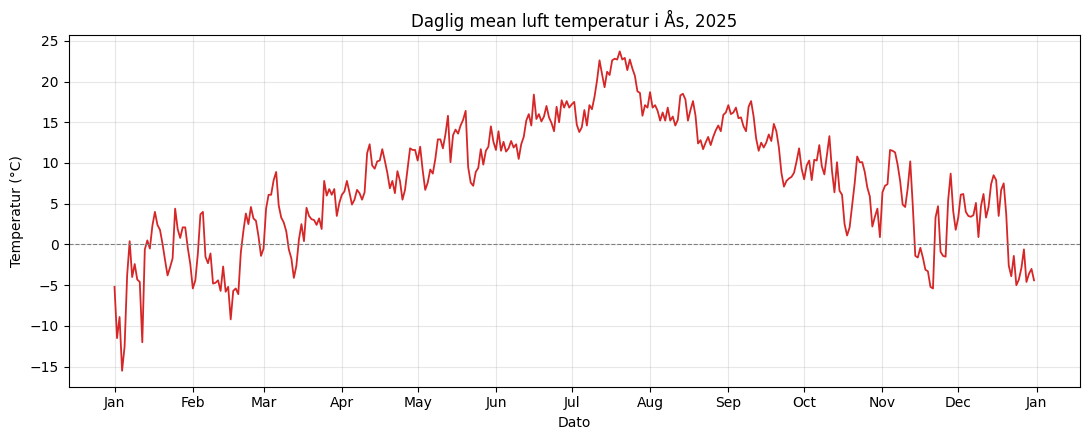

In [4]:
# Plotte datene på tabell
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(temp.index, temp.values, color="tab:red", linewidth=1.3)
ax.set_title(f"Daglig mean luft temperatur i Ås, {YEAR}")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [5]:
#Printer ut oppsumering av tempraturen ila året
print(f"Oppsumering av daglig temperatur, Ås {YEAR}")
print(summary_table({str(YEAR): temp}).to_string())

Oppsumering av daglig temperatur, Ås 2025
                 2025
Mean (°C)         7.9
Median (°C)       8.3
Min (°C)        -15.5
Max (°C)         23.7
Days with data    365


**Discussion (Task 1):**  Kurven ser realistisk ut for temperaturen i Ås, det er også interesannt å se at februar er kaldere enn desember.


## Task 2: Precipitation and temperature together

Temperatur og nedbør er forskjellige og bør derfor ikke vises likt: Temperatur er en kontinuerlig verdi, derfor passer det fint med en **linje** slik vist i oppgave 1. 

Nedbør har en stor variasjon fra dag til dag og ville derfor ikke vært så lett leselig som en linje. Vi har derfor valgt å vise nedbør med **søyle/bar** diagram.

Temperaturen og nedbør har deler tid på x-asken, men får enge y-asker. 
Temperatur på venstre (rød) og nedbør (blå) på høyre

Note (sum(precipitation_amount P1D), 2025): several time offsets {'PT18H': 365, 'PT6H': 365}, using PT18H
Samlet 365 dager med nedbørs data


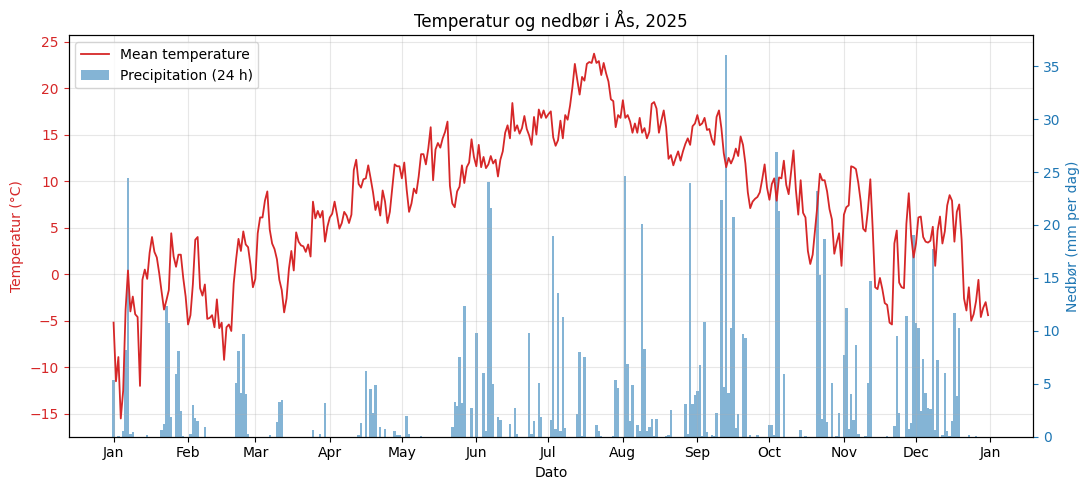

In [ ]:
precip = get_daily(STATION, PRECIP, YEAR)
print(f"Samlet {len(precip)} dager med nedbørs data")

fig, ax_temp = plt.subplots(figsize=(11, 5))
ax_prec = ax_temp.twinx()

bars = ax_prec.bar(precip.index, precip.values, color="tab:blue", alpha=0.55,
                   width=1.0, label="Precipitation (24 h)")
(line,) = ax_temp.plot(temp.index, temp.values, color="tab:red", linewidth=1.3,
                       label="Mean temperature")

# Draw the temperature line on top of the bars
ax_temp.set_zorder(ax_prec.get_zorder() + 1)
ax_temp.patch.set_visible(False)

ax_temp.set_xlabel("Dato")
ax_temp.set_ylabel("Temperatur (°C)", color="tab:red")
ax_prec.set_ylabel("Nedbør (mm per dag)", color="tab:blue")
ax_temp.tick_params(axis="y", colors="tab:red")
ax_prec.tick_params(axis="y", colors="tab:blue")
ax_temp.xaxis.set_major_locator(mdates.MonthLocator())
ax_temp.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_temp.set_title(f"Temperatur og nedbør i Ås, {YEAR}")
ax_temp.grid(alpha=0.3)
ax_temp.legend([line, bars], [line.get_label(), bars.get_label()], loc="upper left")
fig.tight_layout()
plt.show()

**Diskusjon (Oppgave 2):** Vi ser at nedbør og temperatur henger sammen. Om sommeren blir det kaldere dersom det er mye nedbør og om vinteren skjer det motsatte. Antar at dette er pga nedbør (vann) har mindre temperatursvingning enn lufta.

## Task 3: Temperaturen for 100 år siden

Sammenligner data fra 2025 med data fra 1925
Løser på samme måte som task 1

Samlet 365 dager med data for 1925


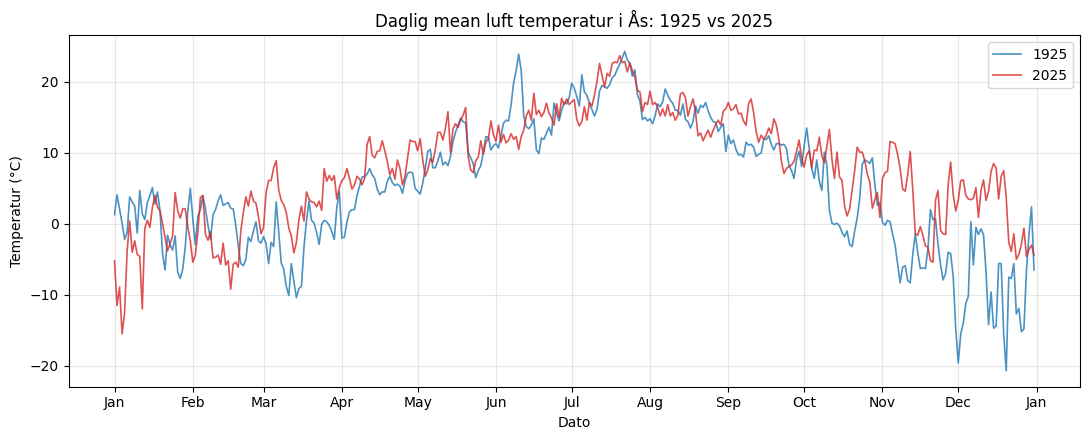

In [7]:
OLD_YEAR = YEAR - 100
temp_old = get_daily(STATION, TEMP_MEAN, OLD_YEAR)
print(f"Samlet {len(temp_old)} dager med data for {OLD_YEAR}")

# Flytter de gamle datoene frem 100år, slik at begge kurvene kan bruke samme x-akse 
temp_old_shifted = temp_old.copy()
temp_old_shifted.index = temp_old.index + pd.DateOffset(years=100)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(temp_old_shifted.index, temp_old_shifted.values, color="tab:blue",
        linewidth=1.2, alpha=0.8, label=str(OLD_YEAR))
ax.plot(temp.index, temp.values, color="tab:red", linewidth=1.2, alpha=0.8, label=str(YEAR))
ax.set_title(f"Daglig mean luft temperatur i Ås: {OLD_YEAR} vs {YEAR}")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [8]:
print(f"Oppsumering av daglige temperaturer, Ås, {OLD_YEAR} vs {YEAR}")
print(summary_table({str(OLD_YEAR): temp_old, str(YEAR): temp}).to_string())

Oppsumering av daglige temperaturer, Ås, 1925 vs 2025
                 1925   2025
Mean (°C)         5.3    7.9
Median (°C)       5.3    8.3
Min (°C)        -20.7  -15.5
Max (°C)         24.3   23.7
Days with data    365    365


**Diskusjon (Oppgave 3):**  Som trend ser vi at klima har blit generelt varme etter 100år. Spesielt interesannt å se at sommerene er stabile, og at det er vintertemperaturen som har økt mest

## Task 4: Heatwaves
En varmebølge i Norge er definert som en periode på 5 minst dager hvor temperaturen har en maximum på minst 27°C

Vi bruker 2 funksjoner:
* `find_heatwaves` - Finner "streaks" hvor **tmax** >= 27 og **min_days** = 5
* `count_heatwaves`- Teller mengden hetebølger for en stasjon. Lager også en summary YAML fil, hvor man kan lese av datene.


Vi teller ikke dager med manglende data i en serie. Dersom en dag mangler data blir hetebølgen brutt.  

In [9]:
def find_heatwaves(tmax, thershold = 27.0, min_days = 5):


    if tmax.empty:
        return []
    #Legger alle dagene i året i en liste slik at mangler kommer opp som NaN
    full = tmax.reindex(pd.date_range(tmax.index.min(), tmax.index.max(), freq = "D"))
    hot = full >= thershold
    run_id = (hot != hot.shift(fill_value=False)).cumsum()

    waves = []
    for _, run in full[hot].groupby(run_id[hot]):
        if len(run) >= min_days:
            waves.append({
                "start" : run.index[0].date(),
                "end" : run.index[-1].date(),
                "lenght_days" : int(len(run)),
                "max_temperature" : float(run.max())
            })
    return waves

def count_heatwaves(station, year, outfile=None, thershold= 27.0, min_days = 5):


    station_id = resolve_station(station)
    tmax = get_daily(station_id, TEMP_MAX, year)
    waves = find_heatwaves(tmax, thershold, min_days)

    summary = {
        "staion" : station_id,
        "year" : year,
        "thershold_celsius" : thershold,
        "min_consecutive_days" : min_days,
        "number_of_heatwaves" : len(waves),
        "heatvaves" : waves, 
    }

    outfile = outfile or f"heatwaves_{station_id}_{year}.yml"
    
    with open (outfile, "w" , encoding="utf-8") as f:
        yaml.safe_dump(summary, f, sort_keys=False, allow_unicode=True)
    return len(waves)

In [10]:
n = count_heatwaves(STATION, YEAR)
print(f"Number of heatwaves in Ås in {YEAR}: {n}")
print(Path(f"heatwaves_{STATION}_{YEAR}.yml").read_text())

Note (max(air_temperature P1D), 2025): several time offsets {'PT18H': 365, 'PT0H': 364}, using PT18H
Number of heatwaves in Ås in 2025: 1
staion: SN17850
year: 2025
thershold_celsius: 27.0
min_consecutive_days: 5
number_of_heatwaves: 1
heatvaves:
- start: 2025-07-16
  end: 2025-07-22
  lenght_days: 7
  max_temperature: 30.8



**Diskusjon (Oppgave 4):** I 2025 var det en hetebølge i Ås, den varte i 7 dager og var 30.8 grader på det varmeste.  

## Task 5: 7-day moving average

Vi sentrerer `moving average`/ glidende gjennomsnitt på dag *t* som er medianen mellom *t-3 ... t+3* for å unngå at greafen blir forsjøvet i forhold til datene. De første og siste 3 dagene i året har ikke et fullt "vindu" rundt seg og blir derfor stående som `Nan`

In [11]:
def moving_average(values, window=7, center=True):
    """Moving average of `values`. Output has the same length as the input;
    positions without a full window are NaN."""
    
    values = np.asarray(values, dtype=float)
    if window < 1 or window > len(values):
        raise ValueError("vinduet må være mellom 1 og len(values)")
    averaged = np.convolve(values, np.ones(window) / window, mode="valid")
    out = np.full(len(values), np.nan)
    start = window // 2 if center else window - 1
    out[start:start + len(averaged)] = averaged
    return out


# Cross-check against pandas on the real data
check = pd.Series(temp.values).rolling(7, center=True).mean().to_numpy()
assert np.allclose(moving_average(temp.values), check, equal_nan=True)
print("moving_average fungerer med pandas rolling mean")

moving_average fungerer med pandas rolling mean


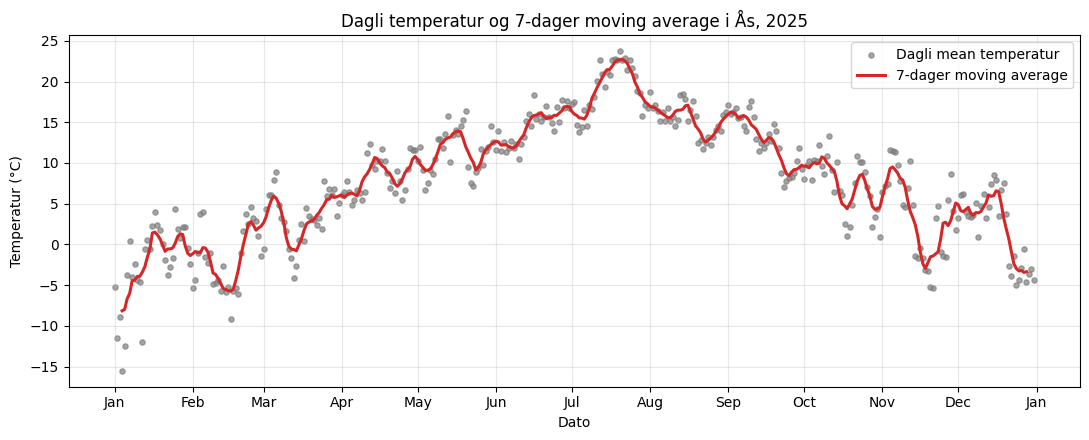

In [12]:
# Put every day of the year in the series so a missing day stays a gap instead of
# silently shifting the window
full_year = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D")
temp_full = temp.reindex(full_year)
temp_ma = moving_average(temp_full.values, window=7)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(temp_full.index, temp_full.values, s=14, color="tab:grey", alpha=0.7,
           label="Dagli mean temperatur")
ax.plot(temp_full.index, temp_ma, color="tab:red", linewidth=2.2,
        label="7-dager moving average")
ax.set_title(f"Dagli temperatur og 7-dager moving average i Ås, {YEAR}")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


**Diskusjon (Task 5):** `moving average` Gjør det lettere å se gjenerelle trender i temperaturen. Det blir lettere å anta en ca. temperatur for en periode i året. 

## Kilder

* Meterologisk institutt, *Frost API*, https://frost.met.no
* Meterologisk institutt, *Python example script*, https://frost.met.no/python_example.html
  
* GenAI notat.

**GenAI**
Vi brukte en blanding av caludeAI og vs codes innebygde AI assistent.
AI-ene sine største oppagver bestod av:
* Forslag til fremgangsmåte
* Hjelp med feilsøking
* Hjelp med testing - kunstige tester hvor vi brukte egne oppdiktede data for å verifisere programmets funksjon. Dette ble brukt mest i forbindelse med Task 4 og 5.   

## Bruk av generativ KI (generet av KI)

Vi brukte Claude (Anthropic, modellen Claude Sonnet 5.5) som hjelpemiddel i denne innleveringen. Under er en oppsummering av samtalen.

### Hva KI-en gjorde

1. **Startutkast.** Vi la inn oppgaveteksten (PDF) og lenken til MET sitt Python-eksempel for Frost. Claude leste eksempelet og kom med eksempler på hvordan vi kunne gå videre fremover. Claude kom med anbefalinger angående biblioteker og hjalp med tolking av oppgavene. 

2. **Funksjoner.** Calude anbefalte å lage et oppsett med funksjoner som skulle brukes underveis før vi begynte på oppgavene. Dette var for å spare tid og unngå å gjøre det samme flere ganger.  Utkastet til Calude anbefalte 4 funskjoner : `load_client_id`, `frost_get`, `get_daily`, `resolve_station`

3. **Endringer fra MET-eksempelet.**
   - `DataFrame.append` finnes ikke lenger i dagens pandas og ble erstattet av en liste med rader.
   - Frost kan returnere flere parallelle tidsserier for samme dag (ulik `timeOffset`). Dette håndteres slik at hver dag bare telles én gang.
   - Tidsintervallet går til 1. januar året etter, fordi vi tror sluttdatoen i Frost er eksklusiv.

4. **Testing.** Claude testet koden vi lagde mot falske data som etterligner Frosts svarformat, ikke mot det ekte API-et. Dette var for å verifisere at programmet fungerte som planlagt

5. **Forklaring.** Claude ga anbeflainger til punker vi burde gå gjennom i videoen


### Referanser
- Claude (Anthropic), brukt som beskrevet over.